# E-Commerce Customer Segmentation: DBSCAN, Hierarchical Clustering & K-Means

### A Comparative Analysis of DBSCAN, Hierarchical Clustering, and K-Means in E-Commerce

**Project Type:** Unsupervised Machine Learning | Customer Analytics  
**Dataset:** E-Commerce Customer Behavior  
**Methods:** DBSCAN, Hierarchical Agglomerative Clustering (HAC), K-Means Baseline  
**Tools:** Python, Pandas, NumPy, Scikit-learn, SciPy, Matplotlib, Seaborn

## Executive Summary

Density-Based and Hierarchical Customer Segmentation: An E-Commerce Behavioral Analysis

**Objective:** This project investigates whether e-commerce customers exhibit distinct behavioral segments and whether differences in digital engagement correspond to meaningful differences in purchasing activity.

**Dataset:** I analyzed 51,289 transaction-level records, aggregated into 795 unique customer profiles. After data cleaning, feature engineering, and exploratory analysis, I developed two clustering representations: a baseline model using purchasing and browsing features, and an engagement-aware model incorporating a composite engagement score.

**Methodology:** I applied DBSCAN, Hierarchical Agglomerative Clustering (Single, Complete, Average, and Ward linkage), and K-Means. Model evaluation included Silhouette Scores, Davies–Bouldin Index, DBSCAN parameter sensitivity, cluster profiling, and Adjusted Rand Index (ARI) comparisons.

## Key Findings:

* Two consistent behavioral segments emerged: high-engagement and low-engagement customers.
* High-engagement customers averaged 21.25 minutes of browsing, compared with 13.17 minutes for low-engagement customers.
* Despite substantial engagement differences, both segments averaged approximately 64.5 orders per customer, with relatively small differences in average order value.
* Ward HAC and K-Means agreed on 794 of 795 customer assignments (99.87%).
* DBSCAN and Ward HAC achieved perfect agreement (ARI = 1.000) among the 757 customers assigned to non-noise DBSCAN clusters.

**Business Insight:** Higher digital engagement did not correspond to substantially higher purchasing frequency or average order value in this dataset. This finding highlights the importance of evaluating engagement and purchasing behavior separately rather than assuming that more interactions automatically indicate greater customer value.

**Conclusion**: The project demonstrates how comparing clustering algorithms can strengthen confidence in descriptive customer segments while emphasizing that algorithmic consistency alone does not establish business value. Further validation using customer journeys, conversion outcomes, and controlled experiments is needed before translating these segments into operational decisions.

## Step 1_ Project Introduction

### Project Overview

Customer segmentation helps e-commerce businesses understand differences in purchasing behavior and digital engagement. Identifying meaningful customer groups can support more targeted marketing, customer retention strategies, and personalized experiences.

In this project, I investigate customer segmentation using two complementary unsupervised learning approaches: Density-Based Spatial Clustering of Applications with Noise (DBSCAN) and Hierarchical Agglomerative Clustering (HAC).

I use K-Means as a baseline to evaluate whether density-based and hierarchical methods reveal meaningful customer structures that centroid-based clustering may overlook.

Rather than assuming that one algorithm is universally superior, I compare clustering solutions based on their internal structure, robustness, interpretability, and potential business relevance.

### Research Questions

1. Can DBSCAN identify meaningful customer groups and unusual behavioral patterns?
2. How do different linkage methods affect hierarchical clustering results?
3. How do DBSCAN and HAC compare with K-Means under consistent feature preparation?
4. Which clustering solutions provide interpretable and actionable customer segments?

### Analytical Approach

The analysis follows six stages:

1. Data preparation and customer-level feature engineering.
2. Exploratory analysis and feature scaling.
3. DBSCAN modeling and parameter sensitivity analysis.
4. Hierarchical clustering and linkage comparison.
5. Model evaluation and cluster profiling.
6. Business interpretation, limitations, and recommendations.

### Expected Contribution

This project extends customer segmentation beyond centroid-based clustering by investigating density, hierarchical relationships, and clustering stability. The goal is to evaluate whether alternative clustering methods provide useful and interpretable insights into e-commerce customer behavior.

## Step 2_ Import Libraries and Load Dataset

### Data Loading and Initial Inspection

I begin by importing the required Python libraries and loading the original e-commerce dataset.

The dataset contains transaction-level information, including customer identifiers, purchasing activity, financial variables, and digital engagement indicators.

Before clustering, I will examine the dataset structure and prepare a consistent customer-level representation. This is important because the objective is to segment customers rather than individual transactions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load the original dataset
df = pd.read_csv("E_commerce.csv", low_memory=False)

# Initial dataset inspection
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Unique customers: {df['Customer ID'].nunique():,}")
print(f"Total missing values: {df.isna().sum().sum():,}")

display(df.head())

Dataset shape: 51,289 rows × 27 columns
Unique customers: 795
Total missing values: 77


,Customer ID,Customer Name,Segment,City,State,Country,Region,Gender,Age,Education,Marital Status,Order ID,Order Date,Months,Ship Mode,Product Category,Product,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Browsing Time (min),Like,Share,Add to Cart
0,LS-001,Lane Daniels,Consumer,Brisbane,Queensland,Australia,Oceania,Male,22,Associate Degree,Married,AU-2024-1,2024/9/15,Nov,First Class,Auto & Accessories,Car Media Players,$140.00,2,0.05,$46.00,$4.60,Medium,14.7,1,1,1
1,IZ-002,Alvarado Kriz,Home Office,Berlin,Berlin,Germany,Central,Male,32,Bachelor,Married,AU-2024-2,2024/6/30,Jun,First Class,Auto & Accessories,Car Speakers,$211.00,3,0.03,$112.00,$11.20,Medium,15.0,0,0,1
2,EN-003,Moon Weien,Consumer,Porirua,Wellington,New Zealand,Oceania,Male,21,High School,Single,AU-2024-3,2024/5/15,Dec,First Class,Auto & Accessories,Car Body Covers,$117.00,5,0.01,$31.20,$3.10,Critical,19.9,1,1,1
3,AN-004,Sanchez Bergman,Corporate,Kabul,Kabul,Afghanistan,Central Asia,Male,22,Bachelor,Married,AU-2024-4,2024/9/15,May,First Class,Auto & Accessories,Car & Bike Care,$118.00,2,0.05,$26.20,$2.60,High,15.8,1,1,1
4,ON-005,Rowe Jackson,Corporate,Townsville,Queensland,Australia,Oceania,Male,28,Associate Degree,Single,AU-2024-5,2023/9/15,Jul,First Class,Auto & Accessories,Tyre,$250.00,1,0.04,$160.00,$16.00,Critical,18.1,1,1,1


## Step 3_Data Quality Assessment

Before preprocessing, I assess missing values, duplicate records, and data types to identify potential quality issues.

Since the dataset contains transaction-level observations, repeated customer IDs are expected and should not automatically be treated as duplicates.

The objective is to distinguish legitimate repeated transactions from data-quality problems before constructing customer-level features.

In [2]:
# Assess missing values, duplicates, and data types
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

quality_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing (%)": (missing / len(df) * 100).round(2)
})

print("Columns with missing values:")
display(quality_summary)

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")

print("\nData types:")
display(df.dtypes.to_frame("Data Type").T)

print("\nDataset dimensions:")
print(f"{df.shape[0]:,} records | {df.shape[1]} variables")

Columns with missing values:


,Missing Values,Missing (%)
Region,74,0.14
Order Priority,2,0.00
Quantity,1,0.00



Exact duplicate rows: 0

Data types:


,Customer ID,Customer Name,Segment,City,State,Country,Region,Gender,Age,Education,Marital Status,Order ID,Order Date,Months,Ship Mode,Product Category,Product,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority,Browsing Time (min),Like,Share,Add to Cart
Data Type,object,object,object,object,object,object,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,object,object,float64,int64,int64,int64



Dataset dimensions:
51,289 records | 27 variables


## Step 4_ Data Cleaning and Type Conversion

The initial assessment identified a small number of missing values and no exact duplicate records. Several financial and numerical variables were also stored as text.

I convert relevant variables into appropriate numeric formats and standardize date fields. Missing values in nonessential categorical variables are retained because these variables are not required for the primary clustering analysis.

Records with invalid or missing essential transaction values are excluded only when necessary for reliable customer-level feature engineering.

This approach minimizes unnecessary data loss while maintaining consistency in the analytical dataset.

In [3]:
# Create a working copy of the original dataset
df_clean = df.copy()

# Convert financial and numerical variables
numeric_cols = [
    "Sales", "Profit", "Quantity", "Discount",
    "Shipping Cost", "Browsing Time (min)",
    "Like", "Share", "Add to Cart"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col].astype(str).str.replace(
            r"[$,]", "", regex=True
        ).str.strip(),
        errors="coerce"
    )

# Convert order dates
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"], errors="coerce"
)

# Remove rows missing essential transaction information
essential_cols = [
    "Customer ID", "Order ID", "Order Date",
    "Sales", "Quantity"
]

rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=essential_cols).copy()

# Verify cleaning results
print(f"Original records: {rows_before:,}")
print(f"Cleaned records: {len(df_clean):,}")
print(f"Removed records: {rows_before - len(df_clean):,}")
print(f"Unique customers retained: {df_clean['Customer ID'].nunique():,}")

print("\nMissing values in essential columns:")
display(df_clean[essential_cols].isna().sum().to_frame("Missing"))

print("\nNumerical summary:")
display(df_clean[numeric_cols].describe().round(2))

Original records: 51,289
Cleaned records: 51,286
Removed records: 3
Unique customers retained: 795

Missing values in essential columns:


,Missing
Customer ID,0
Order ID,0
Order Date,0
Sales,0
Quantity,0



Numerical summary:


,Sales,Profit,Quantity,Discount,Shipping Cost,Browsing Time (min),Like,Share,Add to Cart
count,51286.00,51286.00,51286.00,51285.00,51285.00,51286.00,51286.00,51286.00,51286.00
mean,156.44,72.73,3.00,0.03,7.27,17.28,0.57,0.51,0.67
std,65.78,49.10,1.41,0.01,4.91,9.67,0.50,0.50,0.47
min,33.00,0.50,1.00,0.01,0.10,1.00,0.00,0.00,0.00
25%,109.00,25.70,2.00,0.02,2.60,9.30,0.00,0.00,0.00
50%,159.00,67.00,3.00,0.03,6.70,16.50,1.00,1.00,1.00
75%,218.00,120.60,4.00,0.04,12.10,24.60,1.00,1.00,1.00
max,250.00,167.50,5.00,0.05,16.80,40.00,1.00,1.00,1.00


## Step 5_ Customer-Level Feature Engineering

The original dataset contains multiple transaction records per customer. Since the objective is customer segmentation, I aggregate transaction-level observations into one record per unique customer.

I construct two complementary groups of behavioral features:

- **Purchasing behavior:** total sales, number of unique orders, average order value, total quantity, and average profit.
- **Digital engagement:** average browsing time and the proportions of recorded interactions involving likes, shares, and add-to-cart actions.

Order counts are calculated using unique order identifiers to avoid counting multiple product records from the same order as separate purchases.

Engagement indicators are aggregated as record-level averages rather than interpreted as customer conversion probabilities.

This customer-level dataset provides the foundation for the subsequent clustering analysis.

In [4]:
# Aggregate transaction-level data into customer-level features
customer_df = df_clean.groupby("Customer ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order ID", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Avg_Profit=("Profit", "mean"),
    Avg_Browsing_Time=("Browsing Time (min)", "mean"),
    Like_Rate=("Like", "mean"),
    Share_Rate=("Share", "mean"),
    Add_to_Cart_Rate=("Add to Cart", "mean")
).reset_index()

# Calculate average order value
customer_df["Avg_Order_Value"] = (
    customer_df["Total_Sales"] / customer_df["Total_Orders"]
)

# Reorder features for readability
customer_df = customer_df[
    [
        "Customer ID",
        "Total_Sales",
        "Total_Orders",
        "Avg_Order_Value",
        "Total_Quantity",
        "Avg_Profit",
        "Avg_Browsing_Time",
        "Like_Rate",
        "Share_Rate",
        "Add_to_Cart_Rate"
    ]
]

# Validate the customer-level dataset
print(f"Customer-level dataset shape: {customer_df.shape}")
print(f"Unique customers: {customer_df['Customer ID'].nunique():,}")
print(f"Missing values: {customer_df.isna().sum().sum():,}")

display(customer_df.head())

Customer-level dataset shape: (795, 10)
Unique customers: 795
Missing values: 0


,Customer ID,Total_Sales,Total_Orders,Avg_Order_Value,Total_Quantity,Avg_Profit,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
0,AB-00363,8960.0,58,154.482759,178.0,71.253448,22.746552,0.672414,0.672414,0.793103
1,AB-00421,7840.0,45,174.222222,146.0,85.451111,12.937778,0.377778,0.288889,0.511111
2,AB-004408,7747.0,49,158.102041,157.0,67.938776,20.526531,0.734694,0.734694,0.836735
3,AH-00722,8070.0,52,155.192308,163.0,71.963462,22.501923,0.730769,0.634615,0.826923
4,AK-00157,9489.0,62,153.048387,179.0,70.761290,20.422581,0.774194,0.709677,0.854839


## Step 6_ Exploratory Feature Analysis and Correlation

Before applying distance-based clustering algorithms, I examine the distributions and relationships among the engineered customer-level features.

Highly correlated variables may introduce redundant information and disproportionately influence distance calculations. This is particularly important for DBSCAN and hierarchical clustering, which rely on distances between observations.

The objective is to identify a compact and interpretable feature space while preserving meaningful purchasing and engagement behavior.

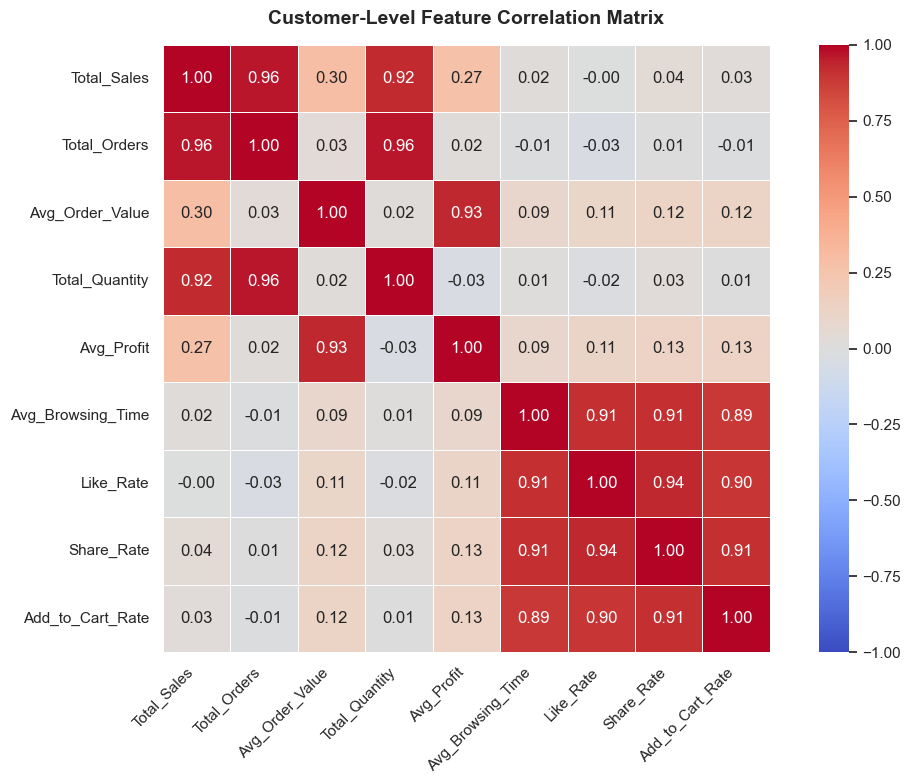

Feature pairs with |correlation| >= 0.80:


Correlation
Total_Orders      Total_Quantity       0.962701
Total_Sales       Total_Orders         0.962437
Like_Rate         Share_Rate           0.936026
Avg_Order_Value   Avg_Profit           0.933192
Total_Sales       Total_Quantity       0.923409
Avg_Browsing_Time Share_Rate           0.911496
                  Like_Rate            0.910515
Share_Rate        Add_to_Cart_Rate     0.910430
Like_Rate         Add_to_Cart_Rate     0.895384
Avg_Browsing_Time Add_to_Cart_Rate     0.886309

In [8]:
# Select numerical customer-level features
feature_df = customer_df.drop(columns=["Customer ID"])

# Calculate Pearson correlations
corr_matrix = feature_df.corr(method="pearson")

# Visualize feature correlations
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(
    "Customer-Level Feature Correlation Matrix",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "figures/02_Customer-Level Feature Correlation Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Identify highly correlated feature pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .loc[lambda x: x.abs() >= 0.80]
    .sort_values(key=abs, ascending=False)
)

print("Feature pairs with |correlation| >= 0.80:")
display(high_corr_pairs.to_frame("Correlation"))

## Step 7 — Behavioral Feature Engineering and Model Design

### Objective

This step develops two alternative feature representations for density-based customer segmentation. The objective is to investigate whether incorporating a composite engagement indicator improves the identification of meaningful customer segments.

**Model A:** Baseline Behavioral Features

The baseline model uses three customer-level features:

* Total_Orders: Customer purchase frequency.
* Avg_Order_Value: Average monetary value per order.
* Avg_Browsing_Time: Average browsing duration.

**Model B:** Engagement-Aware Features

The alternative model replaces browsing time with a composite engagement score constructed from:

* Avg_Browsing_Time
* Like_Rate
* Share_Rate
* Add_to_Cart_Rate

Because these engagement indicators are strongly correlated, a composite score can reduce redundancy while retaining information about overall customer engagement.

Both feature representations will be standardized before clustering. Their performance will subsequently be evaluated using DBSCAN, considering cluster separation, noise levels, cluster sizes, and business interpretability.

Research Question: Does an engagement-aware feature representation produce more meaningful customer segments than a baseline representation based on purchase behavior and browsing time?

In [14]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Step 7: Define baseline and engagement-aware features

baseline_features = [
    "Total_Orders",
    "Avg_Order_Value",
    "Avg_Browsing_Time"
]

engagement_features = [
    "Avg_Browsing_Time",
    "Like_Rate",
    "Share_Rate",
    "Add_to_Cart_Rate"
]

# Model A: Baseline
X_A = customer_df[baseline_features].copy()

# Model B: Composite engagement representation
engagement_scaler = StandardScaler()

engagement_scaled = engagement_scaler.fit_transform(
    customer_df[engagement_features]
)

customer_df["Engagement_Score"] = engagement_scaled.mean(axis=1)

model_b_features = [
    "Total_Orders",
    "Avg_Order_Value",
    "Engagement_Score"
]

X_B = customer_df[model_b_features].copy()

# Standardize both model feature matrices
scaler_A = StandardScaler()
scaler_B = StandardScaler()

X_A_scaled = scaler_A.fit_transform(X_A)
X_B_scaled = scaler_B.fit_transform(X_B)

# Validate outputs
print("Model A shape:", X_A_scaled.shape)
print("Model B shape:", X_B_scaled.shape)

print("\nModel A features:")
print(X_A.columns.tolist())

print("\nModel B features:")
print(X_B.columns.tolist())

print("\nEngagement score summary:")
display(customer_df["Engagement_Score"].describe().round(3))

print("\nMissing values:")
print("Model A:", X_A.isna().sum().sum())
print("Model B:", X_B.isna().sum().sum())

Model A shape: (795, 3)
Model B shape: (795, 3)

Model A features:
['Total_Orders', 'Avg_Order_Value', 'Avg_Browsing_Time']

Model B features:
['Total_Orders', 'Avg_Order_Value', 'Engagement_Score']

Engagement score summary:


count    795.000
mean       0.000
std        0.966
min       -1.594
25%       -0.948
50%        0.508
75%        0.919
max        1.567
Name: Engagement_Score, dtype: float64


Missing values:
Model A: 0
Model B: 0


## Step 8 — DBSCAN Model Comparison and Parameter Exploration

### 8.1 Exploring Neighborhood Distances

DBSCAN identifies clusters as dense regions separated by areas of lower point density. Its results depend primarily on two parameters:

* eps: The maximum neighborhood radius used to identify nearby observations.
* min_samples: The minimum number of observations required within a point’s neighborhood, including the point itself, for that point to qualify as a core sample.

Before fitting DBSCAN, we examine the distribution of distances to each observation’s nearest neighbors for both feature representations.

A sorted k-nearest-neighbor distance plot can help identify candidate values of eps. However, a visible elbow is not guaranteed, and the plot alone does not establish the optimal clustering configuration.

We use the same neighborhood size for both models to support an initial comparison, while allowing each model to have its own appropriate eps range.


Model A — Baseline
0.50    0.380
0.75    0.493
0.85    0.567
0.90    0.645
0.95    0.799
0.98    0.985
dtype: float64

Model B — Engagement-Aware
0.50    0.366
0.75    0.480
0.85    0.558
0.90    0.626
0.95    0.746
0.98    0.986
dtype: float64


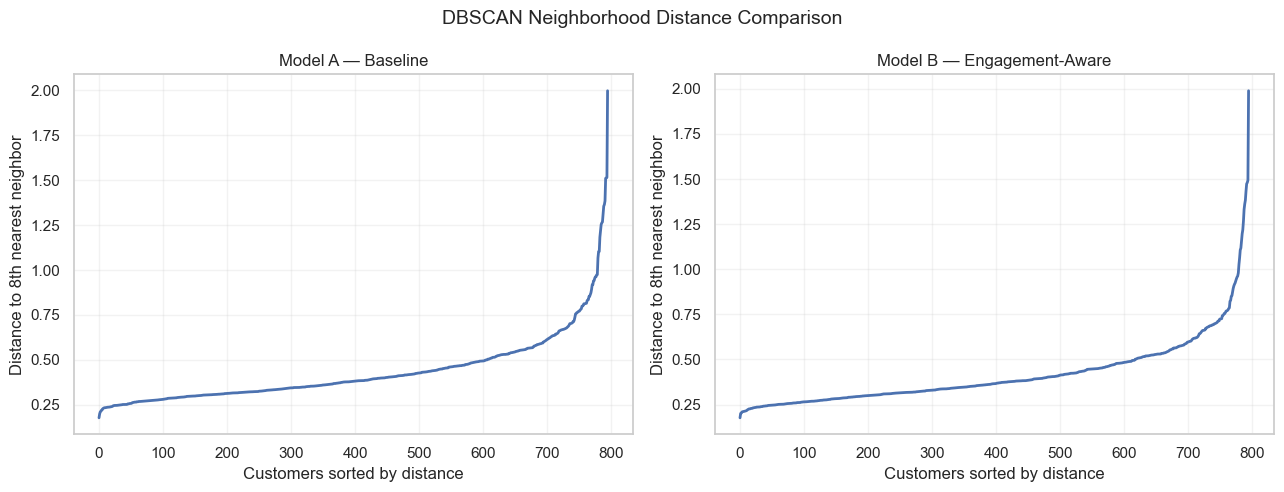

In [15]:
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

min_samples = 8

models = {
    "Model A — Baseline": X_A_scaled,
    "Model B — Engagement-Aware": X_B_scaled
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, X) in zip(axes, models.items()):
    nn = NearestNeighbors(n_neighbors=min_samples)
    nn.fit(X)

    distances, _ = nn.kneighbors(X)
    k_distances = np.sort(distances[:, -1])

    ax.plot(k_distances, linewidth=2)
    ax.set_title(name)
    ax.set_xlabel("Customers sorted by distance")
    ax.set_ylabel(f"Distance to {min_samples}th nearest neighbor")
    ax.grid(alpha=0.25)

    print(f"\n{name}")
    print(
        pd.Series(k_distances).quantile(
            [0.50, 0.75, 0.85, 0.90, 0.95, 0.98]
        ).round(3)
    )

plt.suptitle("DBSCAN Neighborhood Distance Comparison", fontsize=14)
plt.tight_layout()

plt.savefig(
    "dbscan_model_comparison_k_distance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8.2 DBSCAN Hyperparameter Exploration

To evaluate the two feature representations, DBSCAN is fitted across a predefined range of neighborhood radii (eps) and minimum neighborhood sizes (min_samples).

For each configuration, the analysis records:

* The number of clusters, excluding noise observations.
* The percentage of customers labeled as noise.
* The Silhouette Score among non-noise observations, when at least two valid clusters are present.
* The sizes of the identified clusters.

Configurations with fewer than two clusters are not eligible for Silhouette evaluation. The results are used to identify promising parameter regions rather than selecting a model solely by its highest Silhouette Score.

A high Silhouette Score may be misleading if the model excludes a substantial fraction of customers as noise or creates very small clusters. Cluster balance, coverage, and parameter stability will therefore be considered in subsequent evaluation.

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = np.round(np.arange(0.45, 0.86, 0.05), 2)
min_samples_values = [5, 8, 10]

results = []

for model_name, X in models.items():
    for eps in eps_values:
        for min_samples in min_samples_values:

            labels = DBSCAN(
                eps=eps,
                min_samples=min_samples
            ).fit_predict(X)

            non_noise = labels != -1
            cluster_labels = np.unique(labels[non_noise])
            n_clusters = len(cluster_labels)

            noise_pct = 100 * (~non_noise).mean()

            sizes = [
                int(np.sum(labels == cluster_id))
                for cluster_id in cluster_labels
            ]

            score = np.nan

            if (
                n_clusters >= 2
                and non_noise.sum() > n_clusters
            ):
                score = silhouette_score(
                    X[non_noise],
                    labels[non_noise]
                )

            results.append({
                "Model": model_name,
                "eps": eps,
                "min_samples": min_samples,
                "Clusters": n_clusters,
                "Noise_%": round(noise_pct, 2),
                "Silhouette": round(score, 3)
                if not np.isnan(score) else np.nan,
                "Cluster_Sizes": sizes,
                "Smallest_Cluster": min(sizes) if sizes else 0
            })

dbscan_results = pd.DataFrame(results)

# Exploratory shortlist: exclude excessive noise and tiny clusters
valid_results = dbscan_results[
    (dbscan_results["Clusters"] >= 2)
    & (dbscan_results["Noise_%"] <= 15)
    & (dbscan_results["Smallest_Cluster"] >= 20)
].copy()

print("Total configurations tested:", len(dbscan_results))
print("Configurations meeting exploratory criteria:", len(valid_results))

print("\nTop configurations for Model A:")
display(
    valid_results[
        valid_results["Model"] == "Model A — Baseline"
    ].sort_values("Silhouette", ascending=False).head(8)
)

print("\nTop configurations for Model B:")
display(
    valid_results[
        valid_results["Model"] == "Model B — Engagement-Aware"
    ].sort_values("Silhouette", ascending=False).head(8)
)

print("\nNumber of clusters across all configurations:")
display(
    pd.crosstab(
        dbscan_results["Model"],
        dbscan_results["Clusters"]
    )
)

Total configurations tested: 54
Configurations meeting exploratory criteria: 27

Top configurations for Model A:


,Model,eps,min_samples,Clusters,Noise_%,Silhouette,Cluster_Sizes,Smallest_Cluster
8,Model A — Baseline,0.55,10,2,9.43,0.374,"[355, 365]",355
7,Model A — Baseline,0.55,8,2,7.55,0.367,"[365, 370]",365
11,Model A — Baseline,0.60,10,2,6.67,0.364,"[369, 373]",369
10,Model A — Baseline,0.60,8,2,4.53,0.356,"[383, 376]",376



Top configurations for Model B:


,Model,eps,min_samples,Clusters,Noise_%,Silhouette,Cluster_Sizes,Smallest_Cluster
28,Model B — Engagement-Aware,0.45,8,2,13.96,0.398,"[336, 348]",336
32,Model B — Engagement-Aware,0.50,10,2,12.96,0.396,"[340, 352]",340
31,Model B — Engagement-Aware,0.50,8,2,10.06,0.386,"[359, 356]",356
35,Model B — Engagement-Aware,0.55,10,2,8.68,0.381,"[363, 363]",363
34,Model B — Engagement-Aware,0.55,8,2,6.42,0.372,"[375, 369]",369
38,Model B — Engagement-Aware,0.60,10,2,6.16,0.372,"[375, 371]",371
37,Model B — Engagement-Aware,0.60,8,2,4.78,0.366,"[382, 375]",375
41,Model B — Engagement-Aware,0.65,10,2,4.53,0.365,"[382, 377]",377



Number of clusters across all configurations:


Clusters,1,2,3,4
Model,,,,
Model A — Baseline,16,6,3,2
Model B — Engagement-Aware,0,23,3,1


### 8.3 Preliminary Cluster Profiling

Although the engagement-aware representation produced slightly higher Silhouette Scores in several comparable configurations, clustering quality cannot be established from internal validation metrics alone.

To assess practical relevance, this exploratory analysis compares the customer profiles identified by Models A and B using the same DBSCAN parameters (eps = 0.60, min_samples = 8).

Cluster profiles are summarized using the original customer-level measurements, including purchase frequency, average order value, browsing time, and engagement rates.

The objective is to determine whether the engagement-aware representation identifies meaningful differences in purchasing behavior, rather than merely reproducing the high- versus low-engagement separation observed in the baseline model.

These results are exploratory and will inform subsequent stability analysis and comparison with hierarchical clustering.

In [17]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score

# Comparable exploratory configurations
labels_A = DBSCAN(
    eps=0.60, min_samples=8
).fit_predict(X_A_scaled)

labels_B = DBSCAN(
    eps=0.60, min_samples=8
).fit_predict(X_B_scaled)

profile_features = [
    "Total_Orders",
    "Avg_Order_Value",
    "Avg_Browsing_Time",
    "Like_Rate",
    "Share_Rate",
    "Add_to_Cart_Rate"
]

for name, labels in [
    ("Model A", labels_A),
    ("Model B", labels_B)
]:
    profile = customer_df[profile_features].copy()
    profile["Cluster"] = labels

    print(f"\n{name} — Cluster sizes:")
    display(profile["Cluster"].value_counts().sort_index())

    print(f"{name} — Cluster means:")
    display(
        profile.groupby("Cluster")[profile_features]
        .mean().round(3)
    )

print("\nAdjusted Rand Index between Model A and Model B:")
print(round(adjusted_rand_score(labels_A, labels_B), 3))


Model A — Cluster sizes:


Cluster
-1     36
 0    383
 1    376
Name: count, dtype: int64

Model A — Cluster means:


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
Cluster,,,,,,
-1,63.861,155.611,18.064,0.602,0.539,0.679
0,64.582,157.694,21.243,0.720,0.675,0.791
1,64.500,155.103,13.179,0.411,0.328,0.539



Model B — Cluster sizes:


Cluster
-1     38
 0    382
 1    375
Name: count, dtype: int64

Model B — Cluster means:


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
Cluster,,,,,,
-1,64.553,156.355,17.962,0.593,0.539,0.689
0,64.529,157.576,21.256,0.721,0.675,0.791
1,64.488,155.152,13.172,0.411,0.328,0.539



Adjusted Rand Index between Model A and Model B:
0.979


## 8.4 Diagnostic Analysis of Purchasing Behavior

The preliminary cluster profiles show that Models A and B identify nearly identical customer segments (Adjusted Rand Index = 0.979). Both representations primarily separate customers by engagement intensity, while purchase frequency and average order value remain similar across the two main clusters.

This raises an important question: do the purchasing variables contain a distinct segmentation structure that is being overshadowed by the stronger engagement patterns?

To investigate, we examine the two-dimensional distribution of purchase frequency and average order value. This diagnostic analysis is intended to assess the visual structure of purchasing behavior before finalizing the feature representation.

A lack of visually distinct groups would not prove that purchasing behavior contains no useful segmentation information, but it would caution against forcing clusters solely to obtain more differentiated business profiles.

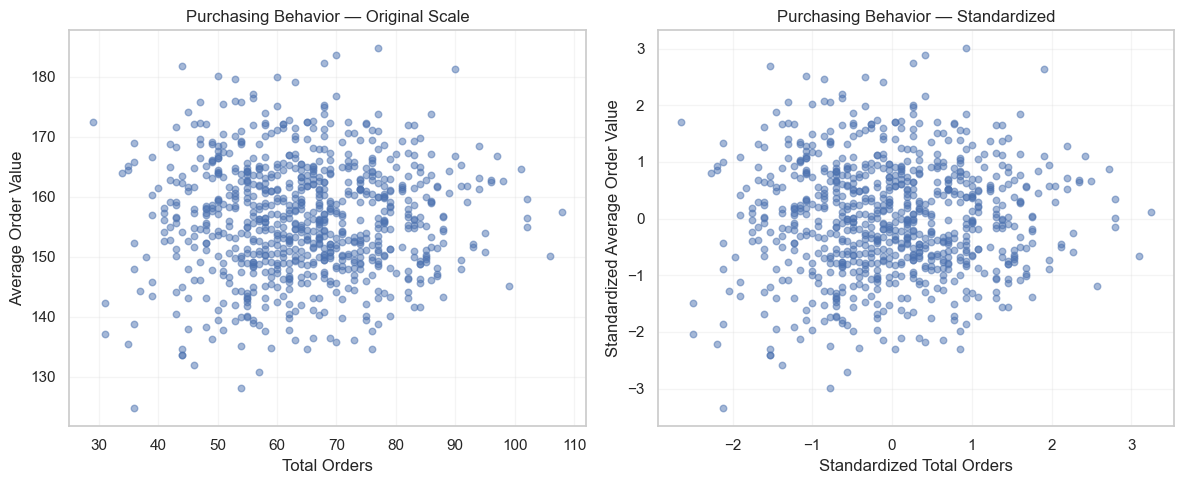

Correlation between purchasing features:


,Total_Orders,Avg_Order_Value
Total_Orders,1.000,0.031
Avg_Order_Value,0.031,1.000


In [18]:


purchase_features = [
    "Total_Orders",
    "Avg_Order_Value"
]

purchase_data = customer_df[purchase_features].copy()

purchase_scaled = StandardScaler().fit_transform(
    purchase_data
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original-scale purchasing behavior
axes[0].scatter(
    purchase_data["Total_Orders"],
    purchase_data["Avg_Order_Value"],
    alpha=0.5,
    s=22
)
axes[0].set_title("Purchasing Behavior — Original Scale")
axes[0].set_xlabel("Total Orders")
axes[0].set_ylabel("Average Order Value")
axes[0].grid(alpha=0.2)

# Standardized purchasing behavior
axes[1].scatter(
    purchase_scaled[:, 0],
    purchase_scaled[:, 1],
    alpha=0.5,
    s=22
)
axes[1].set_title("Purchasing Behavior — Standardized")
axes[1].set_xlabel("Standardized Total Orders")
axes[1].set_ylabel("Standardized Average Order Value")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Correlation between purchasing features:")
display(purchase_data.corr().round(3))

## Step 9 — DBSCAN Sensitivity and Cluster Stability Analysis

### 9.1 Local Parameter Sensitivity

DBSCAN is sensitive to the neighborhood radius (eps) and minimum neighborhood size (min_samples). A clustering solution that changes substantially after small parameter adjustments may be unreliable for practical customer segmentation.

To assess local robustness, we compare nearby parameter configurations against a reference DBSCAN solution with eps = 0.60 and min_samples = 8, using the engagement-aware feature representation (Model B).

#### For each configuration, we evaluate:

* Number of clusters: The number of groups identified, excluding noise.
* Noise percentage: The proportion of customers not assigned to a cluster.
* Adjusted Rand Index (ARI): Agreement with the reference clustering across all customers, including noise labels.
* Cluster sizes: The distribution of customers across the identified groups.

ARI measures agreement between clustering assignments but does not establish that the clusters are meaningful or correct. Including noise observations in ARI calculations also means that changes in noise assignments can affect the score.

The purpose is to assess whether the identified customer segments remain consistent under modest parameter changes, rather than selecting parameters solely to maximize a clustering metric.

DBSCAN Local Sensitivity Results:


,eps,min_samples,Clusters,Noise_%,ARI_vs_Reference,Cluster_Sizes
0,0.50,6,4,6.54,0.931,"[365, 367, 5, 6]"
1,0.50,8,2,10.06,0.890,"[359, 356]"
2,0.50,10,2,12.96,0.833,"[340, 352]"
3,0.55,6,3,3.90,0.989,"[383, 376, 5]"
4,0.55,8,2,6.42,0.966,"[375, 369]"
5,0.55,10,2,8.68,0.919,"[363, 363]"
6,0.60,6,2,3.77,0.979,"[388, 377]"
7,0.60,8,2,4.78,1.000,"[382, 375]"
8,0.60,10,2,6.16,0.971,"[375, 371]"
9,0.65,6,2,2.52,0.954,"[394, 381]"


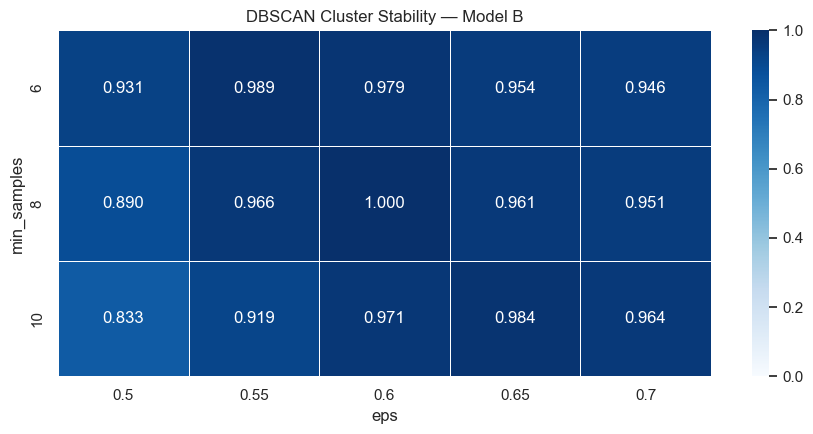

In [19]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
import seaborn as sns

# Reference configuration
reference_eps = 0.60
reference_min_samples = 8

reference_labels = DBSCAN(
    eps=reference_eps,
    min_samples=reference_min_samples
).fit_predict(X_B_scaled)

# Nearby parameter configurations
eps_values = [0.50, 0.55, 0.60, 0.65, 0.70]
min_samples_values = [6, 8, 10]

stability_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(X_B_scaled)

        clusters = np.unique(labels[labels != -1])
        noise_pct = 100 * np.mean(labels == -1)

        ari = adjusted_rand_score(
            reference_labels,
            labels
        )

        cluster_sizes = [
            int(np.sum(labels == cluster))
            for cluster in clusters
        ]

        stability_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": len(clusters),
            "Noise_%": round(noise_pct, 2),
            "ARI_vs_Reference": round(ari, 3),
            "Cluster_Sizes": cluster_sizes
        })

stability_df = pd.DataFrame(stability_results)

print("DBSCAN Local Sensitivity Results:")
display(stability_df)

# Visualize assignment stability
ari_matrix = stability_df.pivot(
    index="min_samples",
    columns="eps",
    values="ARI_vs_Reference"
)

plt.figure(figsize=(9, 4.5))

sns.heatmap(
    ari_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("DBSCAN Cluster Stability — Model B")
plt.xlabel("eps")
plt.ylabel("min_samples")

plt.tight_layout()

plt.savefig(
    "dbscan_cluster_stability_model_b.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.1 Sensitivity Analysis — Findings and Interpretation

The engagement-aware DBSCAN model demonstrated strong local stability across the 15 evaluated parameter configurations.

* Cluster structure: Two primary clusters were identified in 13 of the 15 configurations. The remaining configurations produced additional very small clusters.
* Assignment agreement: Adjusted Rand Index (ARI) values ranged from 0.833 to 1.000, indicating substantial agreement with the reference solution (eps = 0.60, min_samples = 8).
* Noise sensitivity: The proportion of noise observations varied with the neighborhood radius and minimum sample requirement. Larger eps values generally reduced the percentage of observations classified as noise.
* Reference solution: The selected configuration identified two similarly sized clusters containing 382 and 375 customers, with 38 additional observations classified as noise (4.78%).

**Interpretation:** The results suggest that the two main customer segments are not artifacts of a single narrowly chosen parameter configuration. Their membership remains relatively consistent under moderate parameter adjustments.

 **Limitation:** This analysis evaluates local parameter sensitivity using the same dataset. It does not establish out-of-sample stability, causal relationships, or the practical value of the identified segments. The ARI calculations also include noise labels, so some variation reflects changes in noise assignments.

Overall, the reference configuration provides a reasonable basis for subsequent visualization and comparison with hierarchical clustering.

## Step 10 — DBSCAN Cluster Structure and Visualization

### 10.1 Identifying Core, Border, and Noise Observations

DBSCAN distinguishes observations according to their local density and relationship to identified clusters.

* Core observations lie within sufficiently dense neighborhoods.
* Border observations belong to a cluster but do not independently satisfy the core-point density requirement.
* Noise observations are not assigned to any identified cluster.

Using the reference configuration (eps = 0.60, min_samples = 8), we examine the distribution of these point types across the 795 customer profiles.

This analysis provides additional insight into the density structure of the identified segments and helps distinguish stable interior observations from points near cluster boundaries.

In [20]:
# Fit the selected DBSCAN model
dbscan_final = DBSCAN(
    eps=0.60,
    min_samples=8
).fit(X_B_scaled)

dbscan_labels = dbscan_final.labels_

# Identify core observations
core_mask = np.zeros(len(dbscan_labels), dtype=bool)
core_mask[dbscan_final.core_sample_indices_] = True

# Classify observation types
point_types = np.where(
    dbscan_labels == -1,
    "Noise",
    np.where(core_mask, "Core", "Border")
)

# Summary by cluster and point type
dbscan_structure = pd.DataFrame({
    "Cluster": dbscan_labels,
    "Point_Type": point_types
})

print("DBSCAN cluster structure:")
display(
    pd.crosstab(
        dbscan_structure["Cluster"],
        dbscan_structure["Point_Type"],
        margins=True
    )
)

print("\nPoint type percentages:")
display(
    dbscan_structure["Point_Type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

DBSCAN cluster structure:


Point_Type,Border,Core,Noise,All
Cluster,,,,
-1,0,0,38,38
0,27,355,0,382
1,28,347,0,375
All,55,702,38,795



Point type percentages:


Point_Type
Core      88.30
Border     6.92
Noise      4.78
Name: proportion, dtype: float64

### 10.1 Findings: Internal Cluster Structure

The selected DBSCAN configuration classified 795 customers into two clusters and a small noise group.

Of all observations, 702 (88.30%) were core points, 55 (6.92%) were border points, and 38 (4.78%) were classified as noise.

Cluster 0 contained 355 core and 27 border observations, while Cluster 1 contained 347 core and 28 border observations. Therefore, approximately 92.7% of customers assigned to a cluster were core observations.

These findings indicate that both identified clusters contain substantial dense interiors, with relatively few observations located at their boundaries. Together with the parameter sensitivity results, this supports the local structural consistency of the two-cluster solution.

However, density-based classifications describe the geometry of the standardized feature space and should not be interpreted as indicators of customer value or business importance.

### 10.2 Two-Dimensional PCA Visualization

To visualize the density-based segmentation results, the three standardized features of Model B are projected into two principal components using Principal Component Analysis (PCA).

The DBSCAN model was fitted in the original three-dimensional standardized feature space. PCA is used only to display the resulting cluster assignments in two dimensions.

Colors distinguish the two identified clusters and noise observations, while marker styles differentiate core and border observations.

The explained variance ratios are reported to indicate how much of the original feature variation is retained in the visualization. Distances and apparent overlaps in the two-dimensional projection should not be treated as exact representations of the clustering geometry.

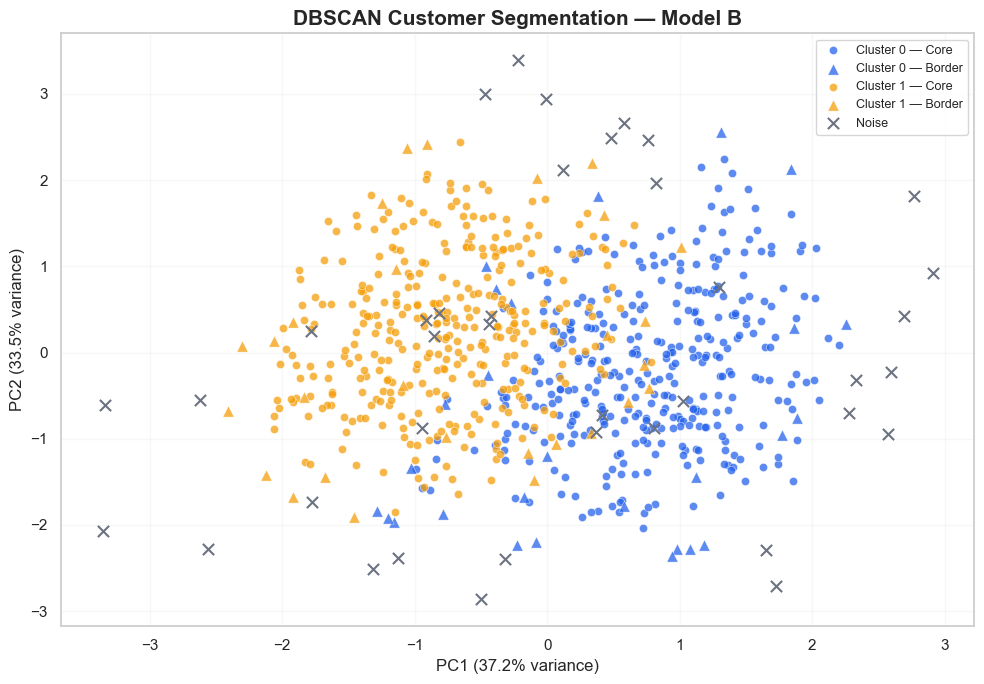

Total variance explained by PC1 and PC2: 70.71%


In [21]:
from sklearn.decomposition import PCA

# PCA for visualization only
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_B_scaled)

explained = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(10, 7))

cluster_colors = {
    0: "#2563EB",
    1: "#F59E0B",
    -1: "#6B7280"
}

for cluster_id in [0, 1]:
    for point_type, marker, size in [
        ("Core", "o", 35),
        ("Border", "^", 65)
    ]:
        mask = (
            (dbscan_labels == cluster_id)
            & (point_types == point_type)
        )

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c=cluster_colors[cluster_id],
            marker=marker,
            s=size,
            alpha=0.75,
            edgecolors="white",
            linewidths=0.4,
            label=f"Cluster {cluster_id} — {point_type}"
        )

# Noise observations
noise_mask = dbscan_labels == -1

ax.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    c=cluster_colors[-1],
    marker="x",
    s=65,
    linewidths=1.5,
    label="Noise"
)

ax.set_title(
    "DBSCAN Customer Segmentation — Model B",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(f"PC1 ({explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}% variance)")

ax.grid(alpha=0.15)
ax.legend(frameon=True, fontsize=9)

plt.tight_layout()

plt.savefig(
    "dbscan_customer_segmentation_model_b.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Total variance explained by PC1 and PC2: "
    f"{explained.sum():.2f}%"
)

### 10.2 PCA Visualization — Findings and Interpretation

The two-dimensional PCA projection explains 70.71% of the total variance, with PC1 accounting for approximately 37.2% and PC2 accounting for 33.5%.

The visualization reveals two partially separated customer groups, with most of their separation occurring along the first principal component. Some overlap remains in the central region of the projection.

Core observations form the main bodies of both clusters, while border and noise observations are distributed more sparsely across the projected space.

Importantly, DBSCAN was fitted using all three standardized features. The two-dimensional PCA projection is used only for visualization and does not fully preserve the original clustering geometry.

Together with the sensitivity analysis and core-point distribution, these findings support a locally stable two-cluster structure. However, the clusters’ business relevance requires separate interpretation and comparison with alternative clustering methods.

## Step 11 — Hierarchical Agglomerative Clustering

### 11.1 Comparing Linkage Methods

Hierarchical Agglomerative Clustering (HAC) begins with each customer as an individual cluster and progressively merges clusters according to a specified linkage criterion.

Unlike DBSCAN, HAC does not require a neighborhood radius or density threshold. Instead, it constructs a hierarchy of nested clusters that can be visualized using a dendrogram.

#### Four linkage strategies are examined:

* Single linkage: Minimum pairwise distance between observations belonging to different clusters.
* Complete linkage: Maximum pairwise distance between observations belonging to different clusters.
* Average linkage: Average pairwise distance between observations in different clusters.
* Ward linkage: Merges clusters to minimize the increase in within-cluster sum of squares.

All methods are applied to the same standardized engagement-aware feature representation used in the DBSCAN analysis.

The dendrograms are compared to examine differences in merging behavior, potential chaining effects, and the presence of distinct hierarchical structures. The number of clusters will be evaluated in the subsequent step rather than selected solely from visual inspection.

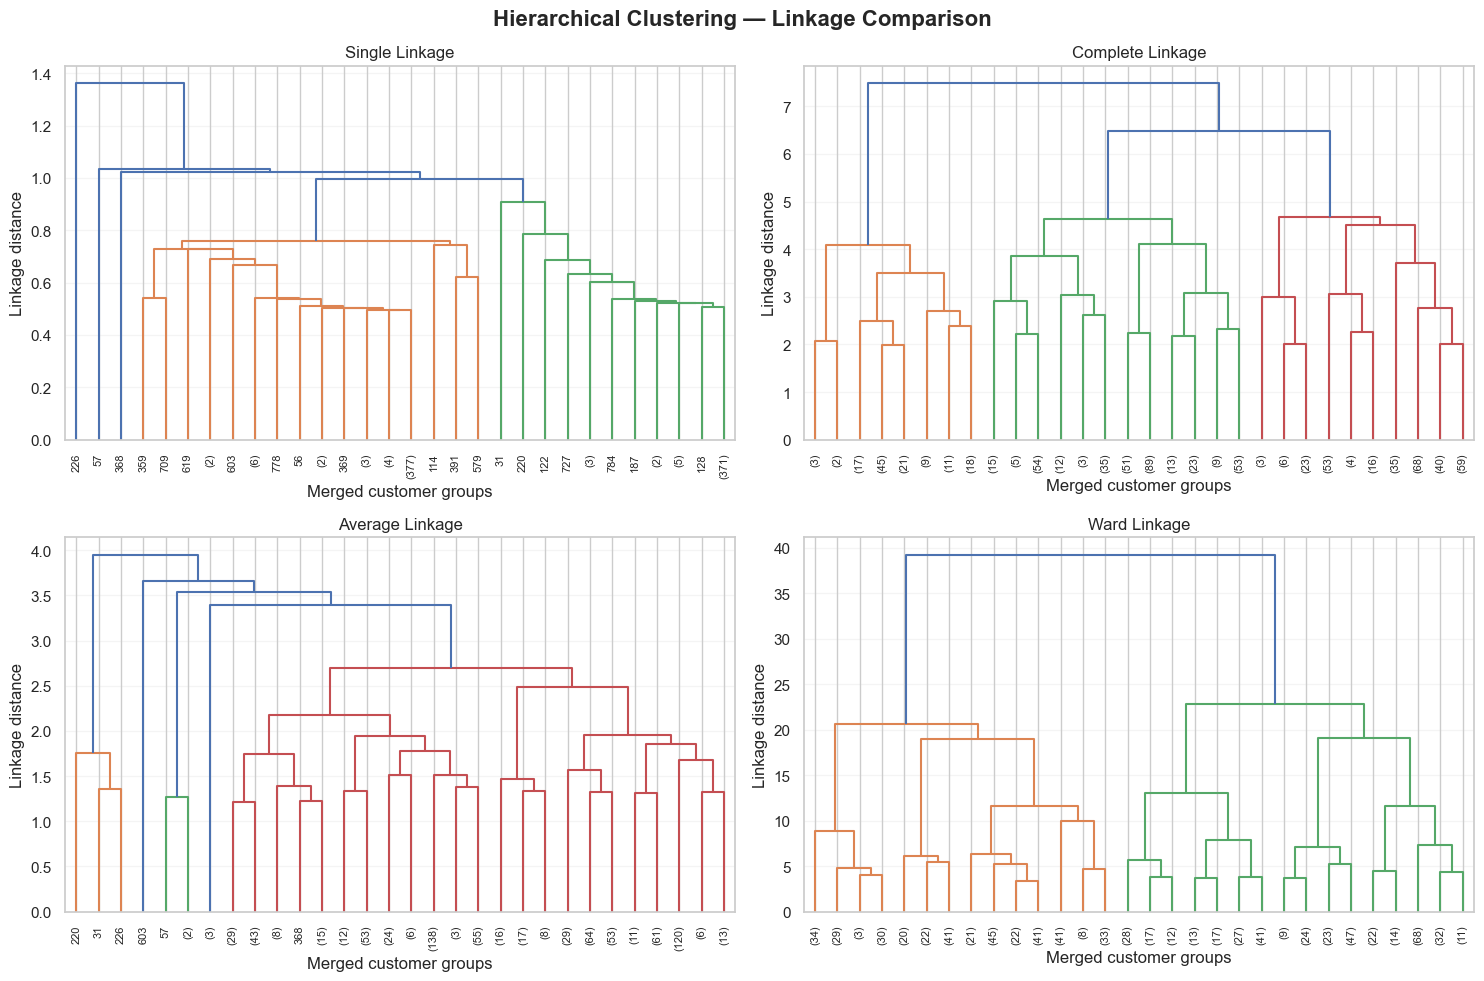

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_methods = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, method in zip(axes.flat, linkage_methods):

    Z = linkage(
        X_B_scaled,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        ax=ax,
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        leaf_rotation=90,
        leaf_font_size=8
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Merged customer groups")
    ax.set_ylabel("Linkage distance")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Hierarchical Clustering — Linkage Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "hac_linkage_comparison_dendrograms.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11.1 Findings — Linkage Method Comparison

The four dendrograms reveal different hierarchical structures under the same standardized engagement-aware feature representation.

Single linkage exhibits a sequence of relatively small-distance merges, consistent with its susceptibility to the chaining effect.

Complete linkage produces more clearly differentiated branches, suggesting that its maximum-distance merging criterion may provide a useful alternative for customer segmentation.

Average linkage shows several smaller branches joining larger groups at relatively high linkage distances, indicating a different sensitivity to isolated observations and group structure.

Ward linkage displays two prominent upper-level branches, with a relatively large increase in linkage height at the final merge. This suggests that a two-cluster solution may be worth investigating.

These observations are exploratory. Dendrogram appearance alone does not establish the optimal linkage method or number of clusters. The next step evaluates candidate solutions using quantitative clustering metrics and cluster-size distributions.

### 11.2 Evaluating Linkage Methods and Cluster Counts

To compare hierarchical clustering solutions, four linkage methods—single, complete, average, and Ward—are evaluated with candidate cluster counts ranging from 2 to 6.

#### Each configuration is assessed using:

* Silhouette Score (higher is better): Measures how well observations fit within their assigned clusters relative to neighboring clusters.
* Davies–Bouldin Index (lower is better): Evaluates within-cluster dispersion relative to separation between clusters.
* Cluster sizes: Identifies highly imbalanced solutions or very small groups that may be difficult to interpret.

All models use the same standardized features as the engagement-aware DBSCAN model.

The metrics provide complementary evidence about cluster geometry. Model selection will also consider dendrogram structure, cluster balance, and whether the resulting groups offer interpretable behavioral distinctions. The highest-scoring configuration will not automatically be treated as the most useful business segmentation.

In [23]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score

hac_results = []

for method in linkage_methods:
    for k in range(2, 7):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method
        )

        labels = model.fit_predict(X_B_scaled)

        silhouette = silhouette_score(
            X_B_scaled, labels
        )

        db_index = davies_bouldin_score(
            X_B_scaled, labels
        )

        sizes = np.bincount(labels)

        hac_results.append({
            "Linkage": method,
            "Clusters": k,
            "Silhouette": round(silhouette, 3),
            "Davies_Bouldin": round(db_index, 3),
            "Smallest_Cluster": int(sizes.min()),
            "Largest_Cluster": int(sizes.max()),
            "Cluster_Sizes": sizes.tolist()
        })

hac_results_df = pd.DataFrame(hac_results)

print("Hierarchical Clustering Evaluation:")
display(
    hac_results_df.sort_values(
        ["Silhouette", "Davies_Bouldin"],
        ascending=[False, True]
    )
)

print("\nBest Silhouette configuration per linkage:")
display(
    hac_results_df.loc[
        hac_results_df.groupby("Linkage")[
            "Silhouette"
        ].idxmax()
    ].sort_values(
        "Silhouette", ascending=False
    )
)

Hierarchical Clustering Evaluation:


,Linkage,Clusters,Silhouette,Davies_Bouldin,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,single,2,0.446,0.401,1,794,"[794, 1]"
10,average,2,0.394,0.721,3,792,"[792, 3]"
15,ward,2,0.345,1.297,390,405,"[405, 390]"
19,ward,6,0.297,0.983,83,211,"[155, 147, 211, 96, 103, 83]"
16,ward,3,0.290,1.240,155,390,"[390, 250, 155]"
18,ward,5,0.273,1.043,96,294,"[294, 147, 155, 96, 103]"
17,ward,4,0.268,1.209,96,294,"[250, 294, 155, 96]"
1,single,3,0.262,0.457,1,793,"[793, 1, 1]"
11,average,3,0.256,0.642,1,791,"[791, 3, 1]"
3,single,5,0.255,0.748,1,404,"[388, 404, 1, 1, 1]"



Best Silhouette configuration per linkage:


,Linkage,Clusters,Silhouette,Davies_Bouldin,Smallest_Cluster,Largest_Cluster,Cluster_Sizes
0,single,2,0.446,0.401,1,794,"[794, 1]"
10,average,2,0.394,0.721,3,792,"[792, 3]"
15,ward,2,0.345,1.297,390,405,"[405, 390]"
6,complete,3,0.220,1.436,126,362,"[307, 126, 362]"


### 11.2 Findings — Selecting the Hierarchical Clustering Configuration

The evaluation revealed an important distinction between internal clustering metrics and the practical interpretability of customer segments.

Single linkage achieved the highest Silhouette Score (0.446) and lowest Davies–Bouldin Index (0.401) with two clusters. However, the solution placed 794 customers in one cluster and only one customer in the other.

Average linkage showed a similar imbalance, separating 792 customers from a group of just three.

Although these configurations scored well on internal metrics, they primarily isolated a small number of observations rather than producing informative customer segments.

Ward linkage with two clusters achieved a Silhouette Score of 0.345 and a Davies–Bouldin Index of 1.297, dividing the 795 customers into two relatively balanced groups of 405 and 390.

Selected configuration: Ward linkage with two clusters.

This configuration was selected as a practical candidate because it avoids extremely small clusters, provides interpretable group sizes, and is consistent with the two prominent upper-level branches observed in the Ward dendrogram.

This selection does not establish that Ward is universally superior. The resulting segments must still be compared with DBSCAN and evaluated using their original customer-level characteristics.

### 11.3 Comparing Ward Hierarchical Clustering with DBSCAN

To examine agreement between clustering approaches, the selected two-cluster Ward solution is compared with the reference engagement-aware DBSCAN model.

### The comparison includes:

* Adjusted Rand Index (ARI): Measures agreement between the two clustering assignments, accounting for chance.
* Cross-tabulation: Shows how customers assigned to DBSCAN clusters and noise are distributed across the Ward clusters.
* Cluster sizes: Compares the overall distribution of customer assignments.

Unlike DBSCAN, Ward hierarchical clustering assigns every customer to a cluster and does not independently label noise observations.

Therefore, agreement is evaluated both across all customers and among customers assigned to non-noise DBSCAN clusters. The latter comparison helps distinguish differences in the two main segments from differences caused by DBSCAN’s treatment of atypical observations.

Cluster labels are arbitrary identifiers; Cluster 0 in one method does not necessarily correspond to Cluster 0 in the other.

In [24]:
# Fit the selected Ward hierarchical clustering model
ward_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

ward_labels = ward_model.fit_predict(X_B_scaled)

# Agreement across all customers
ari_all = adjusted_rand_score(
    dbscan_labels,
    ward_labels
)

# Agreement among DBSCAN non-noise customers
non_noise_mask = dbscan_labels != -1

ari_non_noise = adjusted_rand_score(
    dbscan_labels[non_noise_mask],
    ward_labels[non_noise_mask]
)

# Cross-tabulation of cluster assignments
comparison_table = pd.crosstab(
    pd.Series(dbscan_labels, name="DBSCAN"),
    pd.Series(ward_labels, name="Ward HAC"),
    margins=True
)

print("DBSCAN vs. Ward HAC — Cluster Agreement")
print(f"ARI (all customers): {ari_all:.3f}")
print(f"ARI (DBSCAN non-noise only): {ari_non_noise:.3f}")

print("\nCluster assignment comparison:")
display(comparison_table)

print("\nWard cluster sizes:")
display(
    pd.Series(ward_labels)
    .value_counts()
    .sort_index()
)

DBSCAN vs. Ward HAC — Cluster Agreement
ARI (all customers): 0.906
ARI (DBSCAN non-noise only): 1.000

Cluster assignment comparison:


Ward HAC,0,1,All
DBSCAN,,,
-1,23,15,38
0,382,0,382
1,0,375,375
All,405,390,795



Ward cluster sizes:


0    405
1    390
Name: count, dtype: int64

### 11.3 Findings — Agreement Between DBSCAN and Ward HAC

The comparison revealed exceptionally strong agreement between the two clustering approaches.

The Adjusted Rand Index (ARI) was 0.906 across all 795 customers and 1.000 among the 757 customers assigned to non-noise DBSCAN clusters.

All 382 customers in DBSCAN Cluster 0 were assigned to Ward Cluster 0, while all 375 customers in DBSCAN Cluster 1 were assigned to Ward Cluster 1.

The only assignment differences involved the 38 observations classified as noise by DBSCAN. Ward assigned 23 of these customers to Cluster 0 and 15 to Cluster 1.

Interpretation: Despite using different clustering principles, density-based DBSCAN and variance-minimizing Ward HAC recovered exactly the same two-group partition among DBSCAN’s non-noise observations.

This agreement provides evidence that the identified grouping is not unique to one clustering algorithm. However, both methods were applied to the same dataset and feature representation, so their agreement does not constitute independent validation or establish the business usefulness of the segments.

### 11.4 Ward Cluster Profiling and Business Interpretation

To assess the practical meaning of the Ward hierarchical clustering solution, the two clusters are profiled using customer-level variables in their original units.

The analysis examines purchasing behavior and digital engagement separately:

* Purchasing behavior: Total orders and average order value.
* Digital engagement: Average browsing time, like rate, share rate, and add-to-cart rate.

Comparing these characteristics helps determine whether the Ward clusters represent differences in purchasing value, engagement intensity, or both.

Because Ward assigns all observations to a cluster, the profiles also include the 38 customers previously labeled as noise by DBSCAN.

The results are interpreted descriptively. Differences between clusters do not establish causal relationships or demonstrate that engagement necessarily leads to higher purchasing activity.

Ward HAC — Customer Cluster Profiles:


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
Ward_Cluster,,,,,,
0,64.469,157.452,21.249,0.721,0.676,0.791
1,64.554,155.255,13.169,0.410,0.328,0.538



Ward Cluster Differences vs. Overall Average (%):


,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate
Ward_Cluster,,,,,,
0,-0.1,0.7,22.9,26.8,33.9,18.6
1,0.1,-0.7,-23.8,-27.9,-35.1,-19.3


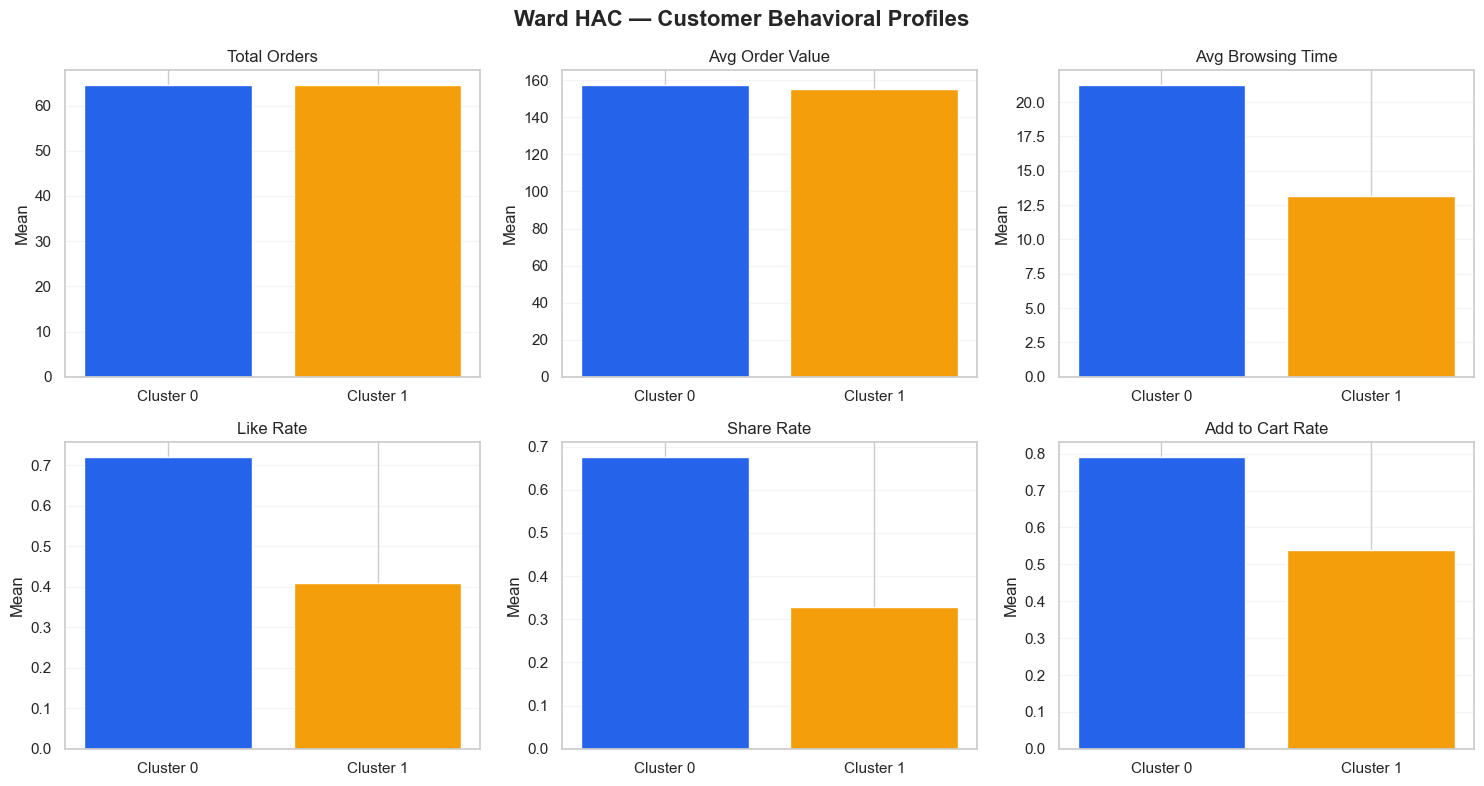

In [25]:
# Customer-level variables for interpretation
profile_features = [
    "Total_Orders",
    "Avg_Order_Value",
    "Avg_Browsing_Time",
    "Like_Rate",
    "Share_Rate",
    "Add_to_Cart_Rate"
]

ward_profile = customer_df[profile_features].copy()
ward_profile["Ward_Cluster"] = ward_labels

# Mean values in original units
ward_means = (
    ward_profile.groupby("Ward_Cluster")[profile_features]
    .mean()
    .round(3)
)

print("Ward HAC — Customer Cluster Profiles:")
display(ward_means)

# Relative differences from the overall customer average
overall_means = customer_df[profile_features].mean()

ward_relative = (
    ward_means.div(overall_means)
    .sub(1)
    .mul(100)
    .round(1)
)

print("\nWard Cluster Differences vs. Overall Average (%):")
display(ward_relative)

# Visual comparison of cluster profiles
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, profile_features):
    ax.bar(
        ["Cluster 0", "Cluster 1"],
        ward_means[feature],
        color=["#2563EB", "#F59E0B"]
    )
    ax.set_title(feature.replace("_", " "))
    ax.set_ylabel("Mean")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Ward HAC — Customer Behavioral Profiles",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "ward_customer_cluster_profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11.4 Findings — Ward Cluster Profiles and Business Interpretation

The two Ward clusters exhibit substantially different digital engagement patterns but relatively similar purchasing behavior.

Cluster 0 — High-Engagement Customers (405 customers):

Customers in this group spend an average of 21.25 minutes browsing, with a like rate of 0.721, share rate of 0.676, and add-to-cart rate of 0.791. Their average number of orders is 64.47, and their average order value is 157.45.

Cluster 1 — Low-Engagement Customers (390 customers):

Customers in this group spend an average of 13.17 minutes browsing, with a like rate of 0.410, share rate of 0.328, and add-to-cart rate of 0.538. Their average number of orders is 64.55, and their average order value is 155.26.

**Key Finding:**

Although Cluster 0 exhibits substantially higher digital engagement, the two clusters have nearly identical purchasing frequency and only a small difference in average order value.

These profiles closely resemble the DBSCAN results. Including the 38 customers previously classified as noise does not materially alter the overall behavioral interpretation.

**Business Interpretation:**

The findings suggest that digital engagement intensity alone may not be a reliable indicator of higher purchasing activity in this dataset. Businesses should avoid assuming that customers who browse, like, or share more necessarily generate substantially greater purchase value.

**Limitations:**

The analysis is descriptive and does not establish causal relationships. Engagement variables are also highly correlated and contribute directly or indirectly to the clustering representation, making differences in engagement partly expected by construction. Further validation would be required before using these segments for operational targeting.

## Step 12 — Comparing DBSCAN, Hierarchical Clustering, and K-Means

### 12.1 Comparative Clustering Evaluation

To assess whether the identified customer segments are consistent across different clustering approaches, three algorithms are compared using the same standardized engagement-aware feature representation:

* DBSCAN: Identifies dense regions and allows observations to remain unassigned as noise.
* Ward Hierarchical Clustering: Builds a hierarchy by minimizing increases in within-cluster variance.
* K-Means: Partitions observations into a predefined number of clusters by minimizing within-cluster squared distances to centroids.

The comparison focuses on two-cluster solutions, consistent with the dominant structure identified in the preceding analyses.

We evaluate Silhouette Scores, cluster sizes, and agreement between customer assignments. For DBSCAN, Silhouette is calculated among non-noise observations, while Ward and K-Means are evaluated on all customers. Consequently, the scores are not directly comparable without considering differences in observation coverage.

The objective is not to declare a universally superior algorithm, but to assess whether the observed segmentation is robust to the choice of clustering method.

In [26]:
from sklearn.cluster import KMeans

# Fit K-Means using the same standardized features
kmeans_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans_model.fit_predict(X_B_scaled)

# Compare clustering assignments
ari_dbscan_kmeans_all = adjusted_rand_score(
    dbscan_labels, kmeans_labels
)

ari_dbscan_kmeans_non_noise = adjusted_rand_score(
    dbscan_labels[non_noise_mask],
    kmeans_labels[non_noise_mask]
)

ari_ward_kmeans = adjusted_rand_score(
    ward_labels, kmeans_labels
)

# Internal validation scores
comparison_metrics = pd.DataFrame([
    {
        "Algorithm": "DBSCAN",
        "Silhouette": silhouette_score(
            X_B_scaled[non_noise_mask],
            dbscan_labels[non_noise_mask]
        ),
        "Customers_Evaluated": int(non_noise_mask.sum()),
        "Noise": int((~non_noise_mask).sum())
    },
    {
        "Algorithm": "Ward HAC",
        "Silhouette": silhouette_score(
            X_B_scaled, ward_labels
        ),
        "Customers_Evaluated": len(ward_labels),
        "Noise": 0
    },
    {
        "Algorithm": "K-Means",
        "Silhouette": silhouette_score(
            X_B_scaled, kmeans_labels
        ),
        "Customers_Evaluated": len(kmeans_labels),
        "Noise": 0
    }
]).round(3)

print("Clustering Performance Comparison:")
display(comparison_metrics)

print("\nAdjusted Rand Index — Algorithm Agreement:")
display(pd.DataFrame({
    "Comparison": [
        "DBSCAN vs. Ward (all customers)",
        "DBSCAN vs. Ward (non-noise)",
        "DBSCAN vs. K-Means (all customers)",
        "DBSCAN vs. K-Means (non-noise)",
        "Ward vs. K-Means"
    ],
    "ARI": [
        ari_all,
        ari_non_noise,
        ari_dbscan_kmeans_all,
        ari_dbscan_kmeans_non_noise,
        ari_ward_kmeans
    ]
}).round(3))

print("\nK-Means Cluster Sizes:")
display(
    pd.Series(kmeans_labels)
    .value_counts()
    .sort_index()
)

C:\Users\azade\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


Clustering Performance Comparison:


,Algorithm,Silhouette,Customers_Evaluated,Noise
0,DBSCAN,0.366,757,38
1,Ward HAC,0.345,795,0
2,K-Means,0.345,795,0



Adjusted Rand Index — Algorithm Agreement:


,Comparison,ARI
0,DBSCAN vs. Ward (all customers),0.906
1,DBSCAN vs. Ward (non-noise),1.000
2,DBSCAN vs. K-Means (all customers),0.906
3,DBSCAN vs. K-Means (non-noise),1.000
4,Ward vs. K-Means,0.995



K-Means Cluster Sizes:


0    404
1    391
Name: count, dtype: int64

## 12.1 Findings — Cross-Algorithm Comparison

The three clustering algorithms produced highly consistent customer segmentation results.

**Clustering quality:**

* DBSCAN achieved a Silhouette Score of 0.366 across 757 non-noise customers, excluding 38 observations classified as noise.
* Ward HAC achieved a Silhouette Score of 0.345 across all 795 customers.
* K-Means achieved a Silhouette Score of 0.345 across all 795 customers.

These scores indicate moderate cluster separation. DBSCAN’s slightly higher score should not be interpreted as evidence of superiority because it was calculated on a reduced set of observations.

**Agreement between algorithms:**

* DBSCAN vs. Ward HAC: ARI = 0.906 across all customers and 1.000 among DBSCAN’s non-noise observations.
* DBSCAN vs. K-Means: ARI = 0.906 across all customers and 1.000 among DBSCAN’s non-noise observations.
* Ward HAC vs. K-Means: ARI = 0.995 across all customers.

The perfect agreement among DBSCAN’s non-noise observations indicates that all three approaches recover the same partition for these 757 customers, up to cluster-label numbering.

**Key Interpretation:**

The identified two-group structure is highly consistent across density-based, hierarchical, and centroid-based clustering methods.

However, this agreement should be interpreted within the selected feature space. All three algorithms were applied to the same standardized variables, and Ward HAC and K-Means were configured to produce two clusters. Therefore, cross-algorithm agreement does not independently establish the existence of two naturally distinct customer populations.

**Business Relevance:**

Combined with the cluster profiles, the results suggest that customers can be separated into high- and low-engagement groups while exhibiting relatively similar purchasing frequency and average order value.

The segmentation provides a descriptive basis for investigating customer engagement patterns, but further validation would be needed before making operational targeting decisions.

## 12.2 Investigating Differences Between Ward HAC and K-Means

Although Ward HAC and K-Means produced nearly identical customer segments (ARI = 0.995), a small difference remains between their cluster assignments.

To investigate this discrepancy, we align the cluster labels across algorithms, identify customers assigned differently, and examine their characteristics.

We also calculate each customer’s distance to the two K-Means centroids. A small difference between these distances indicates that a customer is near the K-Means decision boundary.

Objective: Determine whether the disagreement involves customers with ambiguous cluster membership rather than substantially different behavioral profiles.

In [27]:
# Align K-Means labels with Ward labels
agreement_original = (ward_labels == kmeans_labels).mean()
agreement_flipped = (ward_labels == 1 - kmeans_labels).mean()

kmeans_aligned = (
    kmeans_labels
    if agreement_original >= agreement_flipped
    else 1 - kmeans_labels
)

# Identify customers with different assignments
disagreement_mask = ward_labels != kmeans_aligned

print("Ward vs. K-Means Assignment Comparison:")
print(f"Total customers: {len(ward_labels)}")
print(f"Agreements: {(~disagreement_mask).sum()}")
print(f"Disagreements: {disagreement_mask.sum()}")
print(f"Agreement rate: {(~disagreement_mask).mean():.2%}")

print("\nCluster Assignment Cross-Tabulation:")
display(pd.crosstab(
    pd.Series(ward_labels, name="Ward HAC"),
    pd.Series(kmeans_aligned, name="K-Means"),
    margins=True
))

# Calculate distance to each K-Means centroid
centroid_distances = kmeans_model.transform(X_B_scaled)

# Difference between distances to the two centroids
distance_margin = abs(
    centroid_distances[:, 0] - centroid_distances[:, 1]
)

# Customer-level disagreement analysis
disagreement_df = customer_df[
    ["Customer ID", "Total_Orders", "Avg_Order_Value",
     "Avg_Browsing_Time", "Like_Rate", "Share_Rate",
     "Add_to_Cart_Rate"]
].copy()

disagreement_df["Ward_Cluster"] = ward_labels
disagreement_df["KMeans_Cluster"] = kmeans_aligned
disagreement_df["Centroid_Distance_Margin"] = distance_margin
disagreement_df["Disagreement"] = disagreement_mask

print("\nCustomers Assigned Differently:")
display(
    disagreement_df.loc[disagreement_df["Disagreement"]]
    .round(3)
)

print("\nCentroid Distance Margin Comparison:")
display(
    disagreement_df.groupby("Disagreement")[
        "Centroid_Distance_Margin"
    ].agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

Ward vs. K-Means Assignment Comparison:
Total customers: 795
Agreements: 794
Disagreements: 1
Agreement rate: 99.87%

Cluster Assignment Cross-Tabulation:


K-Means,0,1,All
Ward HAC,,,
0,404,1,405
1,0,390,390
All,404,391,795



Customers Assigned Differently:


,Customer ID,Total_Orders,Avg_Order_Value,Avg_Browsing_Time,Like_Rate,Share_Rate,Add_to_Cart_Rate,Ward_Cluster,KMeans_Cluster,Centroid_Distance_Margin,Disagreement
619,ON-00766,44,133.568,21.025,0.5,0.5,0.705,0,1,0.064,True



Centroid Distance Margin Comparison:


,count,mean,median,min,max
Disagreement,,,,,
False,794,1.118,1.100,0.268,1.944
True,1,0.064,0.064,0.064,0.064


### 12.2 Findings — Investigating Cluster Assignment Differences

Ward HAC and K-Means demonstrated exceptionally high agreement, assigning 794 of 795 customers (99.87%) to corresponding clusters after label alignment.

Only one customer, ON-00766, received different assignments.

**Customer characteristics:**

* Total orders: 44
* Average order value: 133.568
* Average browsing time: 21.025 minutes
* Like rate: 0.500
* Share rate: 0.500
* Add-to-cart rate: 0.705

Ward HAC assigned this customer to Cluster 0, whereas K-Means assigned the customer to Cluster 1.

**Decision-Boundary Analysis:**

The customer’s absolute difference in distance to the two K-Means centroids was only 0.064, compared with a median of 1.100 among the other 794 customers.

Furthermore, the smallest distance margin among the remaining customers was 0.268, indicating that the disputed customer was the closest to the K-Means decision boundary according to this measure.

**Interpretation:**

The disagreement is consistent with a borderline customer whose cluster membership is sensitive to the clustering approach.

The near-identical assignments support the stability of the two-cluster partition across Ward HAC and K-Means within the selected standardized feature space.

However, agreement across algorithms does not independently validate the feature representation or establish that the segments are commercially actionable.

## 13. Final Conclusions and Business Implications

### 13.1 Project Overview

In this project, I investigated whether e-commerce customers exhibit distinct behavioral patterns and whether those patterns are consistently identified by different clustering algorithms.

Using an e-commerce dataset containing 51,289 transaction-level records, I performed data quality checks, cleaned the data, and aggregated customer activity into 795 customer-level observations.

The analysis focused on two complementary dimensions of customer behavior:

* Purchasing behavior: Total orders and average order value.
* Digital engagement: Browsing time, likes, shares, and add-to-cart activity.

I first examined feature distributions and correlations to identify redundancy and guide feature selection. I then compared two clustering representations:

* Model A — Baseline: Total Orders, Average Order Value, and Average Browsing Time.
* Model B — Engagement-Aware: Total Orders, Average Order Value, and a composite Engagement Score derived from correlated engagement indicators.

The clustering analysis included DBSCAN, Hierarchical Agglomerative Clustering (HAC), and K-Means, followed by parameter sensitivity checks, customer profiling, and cross-algorithm agreement analysis.

#### The central research question was:

Can unsupervised clustering identify meaningful customer engagement segments, and do customers with higher digital engagement also exhibit stronger purchasing behavior?

### 13.2 Key Finding 1 — Two Distinct Engagement Profiles

Across the selected clustering approaches, the analysis consistently identified two major customer groups characterized by substantially different digital engagement patterns.

Using the Ward HAC solution, the groups were:

Behavioral Metric	High-Engagement Cluster (n = 405)	Low-Engagement Cluster (n = 390)
Average Browsing Time	21.249 minutes	13.169 minutes
Like Rate	0.721	0.410
Share Rate	0.676	0.328
Add-to-Cart Rate	0.791	0.538
Total Orders	64.469	64.554
Average Order Value	157.452	155.255

The high-engagement group spent approximately 61% more time browsing and demonstrated substantially higher like, share, and add-to-cart rates.

These differences indicate that the clustering approaches successfully distinguished customers according to engagement intensity within the selected feature representation.

However, the engagement indicators were strongly correlated in the original data. Therefore, the separation should not be interpreted as the discovery of several independent behavioral dimensions. Rather, it primarily reflects a common underlying engagement pattern.

### 13.3 Key Finding 2 — Higher Engagement Did Not Correspond to Substantially Higher Purchasing Activity

The most important business finding was the contrast between engagement behavior and purchasing behavior.

Despite the pronounced differences in browsing and social engagement, the two clusters had nearly identical average purchasing frequency:

* High-engagement customers: 64.469 orders.
* Low-engagement customers: 64.554 orders.

Average order value also differed only modestly:

* High-engagement customers: 157.452.
* Low-engagement customers: 155.255.

The difference in average order value was approximately 1.4%, relative to the low-engagement cluster.

These findings suggest that higher digital engagement does not necessarily correspond to meaningfully higher purchasing activity in this dataset.

Customers who browse longer, like more products, and share more content may not purchase substantially more frequently or spend substantially more per order.

This distinction is important because engagement metrics are often used as indicators of customer interest. However, customer interest and purchasing outcomes represent related but different dimensions of behavior.

The findings are descriptive and do not establish that engagement has no commercial value or that increasing engagement would fail to improve purchasing outcomes.

#### 13.4 Key Finding 3 — Strong Consistency Across Clustering Algorithms

I compared three clustering methods with different underlying assumptions:

DBSCAN identifies dense regions of observations and can classify atypical observations as noise.

Ward Hierarchical Clustering progressively merges groups while minimizing increases in within-cluster variance.

K-Means assigns observations to clusters based on their distances to cluster centroids.

The results were highly consistent.

Algorithm	Silhouette Score	Customers Evaluated	Noise
DBSCAN	0.366	757	38
Ward HAC	0.345	795	0
K-Means	0.345	795	0

The Silhouette Scores indicate moderate separation rather than perfectly isolated customer groups.

DBSCAN’s score was calculated after excluding noise observations, so it should not be directly ranked against the full-sample scores of Ward and K-Means.

Cross-algorithm agreement was particularly strong:

Algorithm Comparison	Adjusted Rand Index
DBSCAN vs. Ward HAC — All Customers	0.906
DBSCAN vs. Ward HAC — Non-Noise	1.000
DBSCAN vs. K-Means — All Customers	0.906
DBSCAN vs. K-Means — Non-Noise	1.000
Ward HAC vs. K-Means	0.995

All three methods produced identical partitions for the 757 customers assigned to non-noise DBSCAN clusters, after accounting for arbitrary cluster-label numbering.

This provides strong evidence that the identified grouping is not specific to a single clustering algorithm.

Nevertheless, all three approaches used the same selected feature space, and the Ward and K-Means comparisons used two-cluster solutions. Agreement between algorithms therefore supports consistency within this analytical setup, not independent confirmation of the underlying customer segments.

#### 13.5 Key Finding 4 — Disagreements Were Concentrated Near the Cluster Boundary

Ward HAC and K-Means agreed on the assignments of 794 out of 795 customers, corresponding to a 99.87% agreement rate.

Only one customer, ON-00766, received different cluster assignments.

This customer’s absolute difference in distance to the two K-Means centroids was 0.064, compared with a median of 1.100 among the other customers.

The smallest distance margin among the remaining 794 customers was 0.268.

Therefore, the single disputed customer was the closest observation to the K-Means decision boundary according to the centroid-distance margin.

This result suggests that the small disagreement between Ward and K-Means is consistent with an ambiguous boundary observation rather than a substantially different segmentation structure.

The analysis also demonstrates why cluster assignments should not always be interpreted as definitive customer categories, particularly for observations located near decision boundaries.

#### 13.6 Business Implications and Recommendations

The findings offer several practical directions for further investigation.

**Recommendation 1** — Evaluate Engagement and Purchasing Separately

Businesses should avoid treating high engagement as an automatic indicator of high purchasing value.

Engagement metrics such as browsing time, likes, shares, and add-to-cart activity should be evaluated alongside purchasing metrics such as order frequency, average order value, and revenue.

A combined view can provide a more complete understanding of customer behavior than either dimension alone.

**Recommendation 2** — Investigate the High-Engagement Segment

Customers in the high-engagement segment interact more extensively with the platform without showing substantially higher average purchasing activity.

This raises useful questions:

* Are these customers comparing products before purchasing?
* Do they experience difficulties finding suitable products?
* Does extended browsing reflect greater interest, more complex purchase decisions, or friction in the shopping experience?

The present dataset cannot distinguish among these explanations.

Additional behavioral data, such as session-level conversion events, checkout abandonment, product searches, and navigation paths, would help investigate them.

**Recommendation 3** — Investigate the Low-Engagement Segment

The low-engagement group demonstrates similar purchasing frequency despite spending less time browsing and interacting less with engagement features.

One possible explanation is that some customers reach purchasing decisions with fewer interactions.

However, this interpretation remains a hypothesis rather than an established finding.

Further analysis of customer journeys, repeat purchases, and session-level conversion behavior would be necessary before describing these customers as more efficient or purchase-oriented.

**Recommendation 4** — Test Interventions Before Operational Deployment

The identified segments could support exploratory experiments, such as:

* Testing improved product discovery for high-engagement customers.
* Evaluating simplified navigation and personalized recommendations.
* Comparing the effectiveness of different engagement and purchase-focused messaging strategies.

These interventions should be assessed through controlled experiments with predefined business outcomes.

Cluster membership alone does not establish which intervention will work or whether a segment will respond positively.

#### 13.7 Methodological Limitations

Several limitations should be considered when interpreting the results.

1. Feature Selection and Correlation

Engagement variables exhibited strong correlations. The composite Engagement Score reduced redundancy in the clustering representation, but it did not introduce an independent source of information.

The baseline and engagement-aware representations also produced highly similar segmentation results, suggesting that the main grouping was not substantially changed by replacing browsing time with the composite engagement measure.

2. Moderate Cluster Separation

Silhouette Scores around 0.35 indicate moderate separation. The clusters are useful descriptive groupings, but they should not be interpreted as perfectly distinct or naturally discrete customer populations.

3. Conditional Algorithm Agreement

High agreement across DBSCAN, Ward HAC, and K-Means demonstrates consistency within the chosen standardized feature space.

It does not establish that the same segmentation would emerge under different feature selections, customer populations, or data collection periods.

4. Descriptive, Not Causal, Findings

The analysis does not determine whether engagement causes purchasing behavior.

Observed similarities in purchasing metrics cannot establish the absence of causal effects or rule out relationships that require different measurements or research designs.

5. Customer-Level Aggregation

Aggregating transaction-level observations into customer-level summaries simplifies the analysis but removes information about behavioral sequences, changes over time, and individual shopping sessions.

6. Limited External Validation

The clusters were evaluated using internal clustering metrics, sensitivity analysis, and agreement across algorithms. Their stability on future data and their ability to support profitable business decisions have not yet been established.

#### 13.8 Future Research

Several extensions could strengthen the analysis.

Temporal Validation: Recreate customer features across different time periods and examine whether customers retain similar segment memberships.

Alternative Feature Representations: Investigate whether additional purchasing, recency, or customer-lifecycle variables reveal commercially meaningful distinctions not captured by the current features.

Customer Journey Analysis: Incorporate session-level behavior, checkout activity, and conversion outcomes to understand how browsing and engagement relate to purchasing decisions.

Experimental Evaluation: Use randomized A/B tests to determine whether interventions tailored to engagement segments improve relevant business outcomes.

Out-of-Sample Assessment: Evaluate whether the identified customer patterns remain stable on new observations or an independent dataset with comparable variables.

### 13.9 Final Conclusion

This project demonstrated how unsupervised machine learning can be used not only to segment e-commerce customers but also to critically evaluate whether those segments provide meaningful behavioral and business insights.

Across DBSCAN, Ward Hierarchical Clustering, and K-Means, I identified a highly consistent two-group structure separating customers primarily by digital engagement intensity.

The most important finding was that substantial differences in engagement were accompanied by relatively small differences in purchasing frequency and average order value.

The strong agreement across clustering methods supports the consistency of this descriptive segmentation, while the moderate Silhouette Scores and correlated engagement variables highlight the importance of cautious interpretation.

Ultimately, the analysis illustrates a broader lesson in applied data science:

A statistically consistent customer segmentation is not automatically a commercially valuable segmentation.

The practical value of customer clusters depends on whether they reveal actionable differences, support meaningful decisions, and produce measurable improvements when tested in real business settings.